# 🔍 Análisis Exploratorio de Datos (EDA) - Riesgo de Crédito

**Objetivo:** Comprender la estructura del dataset `imodels/credit-card`, verificar la calidad de los datos (nulos/duplicados) y analizar la distribución de la variable objetivo de impago (`default.payment.next.month`).

In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Permitir importaciones desde la raíz del proyecto
sys.path.append('..')
from src.ingesta import cargar_datos_huggingface

# Configuración visual
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

/workspaces/ml-riesgo-credito/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga e Inspección General

In [2]:
df = cargar_datos_huggingface()
print(f"Dimensiones: {df.shape[0]} filas, {df.shape[1]} columnas")
df.head()

📡 Descargando dataset desde Hugging Face: 'imodels/credit-card'...
✅ Ingesta finalizada con éxito.
📊 Tamaño del DataFrame: 24000 filas x 34 columnas.

Dimensiones: 24000 filas, 34 columnas


,limit_bal,age,pay_0,pay_2,pay_3,pay_4,pay_5,pay_6,bill_amt1,bill_amt2,bill_amt3,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,sex:1,sex:2,education:0,education:1,education:2,education:3,education:4,education:5,education:6,marriage:0,marriage:1,marriage:2,marriage:3,default.payment.next.month
0,80000.0,24.0,0.0,0.0,0.0,0.0,0.0,0.0,75125.0,77353.0,78321.0,73731.0,39643.0,39457.0,3503.0,5001.0,2092.0,1218.0,1445.0,878.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
1,30000.0,28.0,0.0,0.0,0.0,0.0,0.0,0.0,29242.0,29507.0,29155.0,25255.0,22001.0,0.0,5006.0,1244.0,851.0,955.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
2,180000.0,44.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,20916.0,0.0,850.0,0.0,6881.0,10340.0,0.0,850.0,0.0,6881.0,10340.0,182.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0
3,60000.0,25.0,0.0,0.0,0.0,0.0,0.0,0.0,58839.0,53235.0,38533.0,39639.0,39619.0,39140.0,2018.0,1900.0,2000.0,1500.0,1900.0,2000.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
4,130000.0,25.0,0.0,0.0,0.0,0.0,0.0,0.0,111587.0,112348.0,114734.0,117823.0,120854.0,123904.0,4100.0,4200.0,5000.0,5000.0,5000.0,10700.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0


## 2. Calidad de Datos (Nulos y Duplicados)

In [3]:
print("--- Resumen de Datos Faltantes ---")
print(f"Total de nulos: {df.isnull().sum().sum()}")
print(f"Filas duplicadas: {df.duplicated().sum()}")

--- Resumen de Datos Faltantes ---
Total de nulos: 0
Filas duplicadas: 25


## 3. Distribución de la Variable Objetivo (Desbalance de Clases)

/tmp/ipykernel_41275/2569859531.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=target_col, palette='Set2')


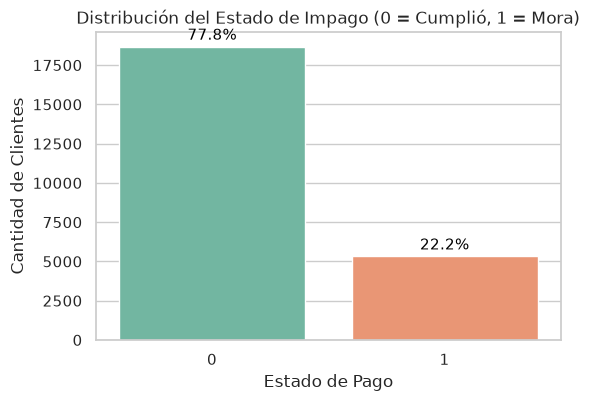

In [4]:
target_col = [c for c in df.columns if 'default' in c.lower()][0]

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x=target_col, palette='Set2')
plt.title('Distribución del Estado de Impago (0 = Cumplió, 1 = Mora)')
plt.xlabel('Estado de Pago')
plt.ylabel('Cantidad de Clientes')

# Mostrar porcentajes en las barras
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')
plt.show()

## 4. Matriz de Correlación

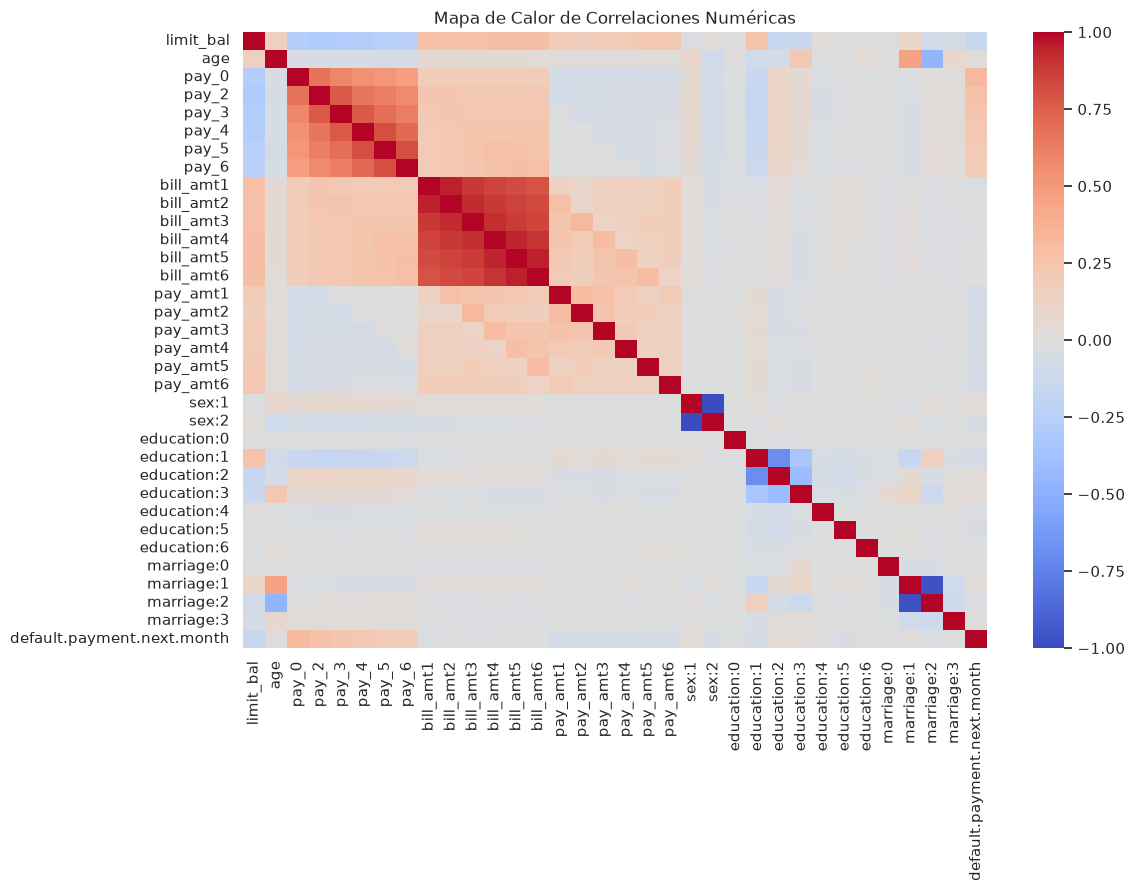

In [5]:
plt.figure(figsize=(12, 8))
correlaciones = df.corr(numeric_only=True)
sns.heatmap(correlaciones, cmap='coolwarm', vmin=-1, vmax=1, annot=False)
plt.title('Mapa de Calor de Correlaciones Numéricas')
plt.show()